<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 5: Bias-Variance, Overfitting and Underfitting Analysis

**Category**: CO1 – Mathematical Foundations and Optimization  
**Objective**: Analyze polynomial regression models to decompose underfitting and overfitting using training/validation curves and bootstrap variance estimation.


### Task 1: Synthesize Non-Linear Data and Polynomial Fitting


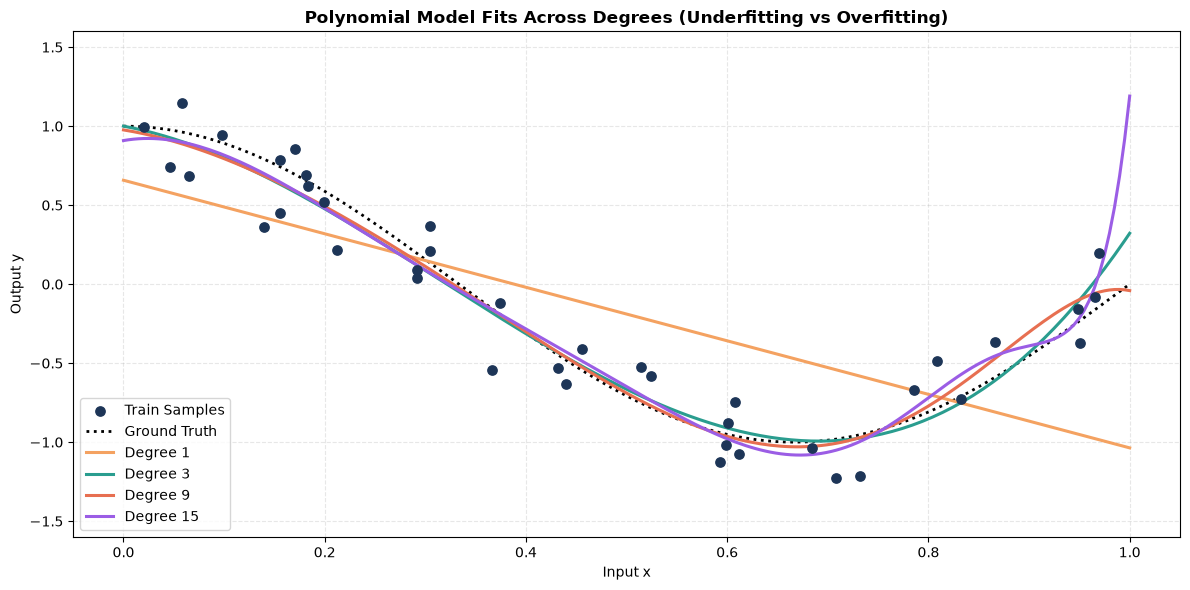

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

np.random.seed(42)
n_samples = 40

# True function: sinusoidal curve with gaussian noise
def true_target(x):
    return np.cos(1.5 * np.pi * x)

x_train = np.sort(np.random.rand(n_samples))
y_train = true_target(x_train) + np.random.normal(0, 0.22, n_samples)

x_val = np.sort(np.random.rand(80))
y_val = true_target(x_val) + np.random.normal(0, 0.22, 80)

degrees = [1, 3, 9, 15]
x_dense = np.linspace(0, 1, 200)

plt.figure(figsize=(12, 6))
plt.scatter(x_train, y_train, color='#1d3557', s=45, label='Train Samples', zorder=5)
plt.plot(x_dense, true_target(x_dense), color='black', lw=2, linestyle=':', label='Ground Truth')

colors = ['#f4a261', '#2a9d8f', '#e76f51', '#9b5de5']
for deg, col in zip(degrees, colors):
    model = make_pipeline(PolynomialFeatures(deg), Ridge(alpha=1e-6))
    model.fit(x_train[:, None], y_train)
    y_pred = model.predict(x_dense[:, None])
    plt.plot(x_dense, y_pred, color=col, lw=2.2, label=f'Degree {deg}')

plt.title("Polynomial Model Fits Across Degrees (Underfitting vs Overfitting)", fontweight='bold')
plt.xlabel("Input x")
plt.ylabel("Output y")
plt.ylim(-1.6, 1.6)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


### Task 2: Model Complexity vs Train and Validation Loss


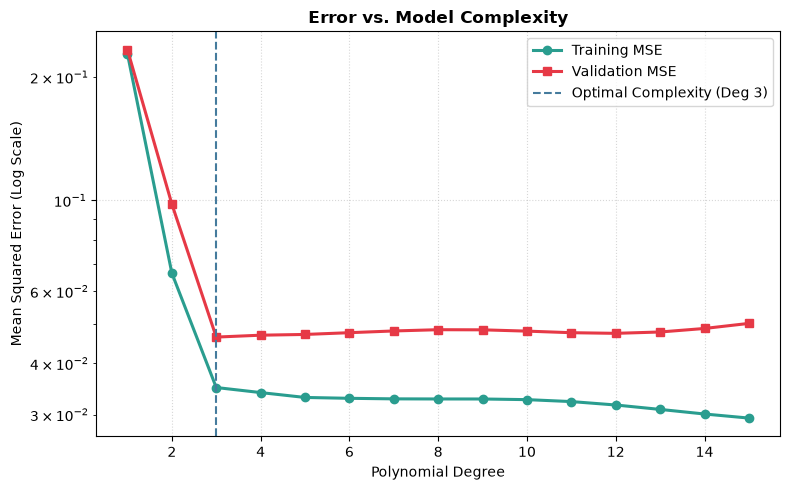

In [2]:
all_degs = list(range(1, 16))
train_losses = []
val_losses = []

for d in all_degs:
    m = make_pipeline(PolynomialFeatures(d), Ridge(alpha=1e-6))
    m.fit(x_train[:, None], y_train)
    train_losses.append(np.mean((m.predict(x_train[:, None]) - y_train) ** 2))
    val_losses.append(np.mean((m.predict(x_val[:, None]) - y_val) ** 2))

plt.figure(figsize=(8, 5))
plt.plot(all_degs, train_losses, color='#2a9d8f', lw=2.2, marker='o', label='Training MSE')
plt.plot(all_degs, val_losses, color='#e63946', lw=2.2, marker='s', label='Validation MSE')
plt.axvline(3, color='#457b9d', linestyle='--', label='Optimal Complexity (Deg 3)')
plt.yscale('log')
plt.title("Error vs. Model Complexity", fontweight='bold')
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error (Log Scale)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Task 3: Bootstrap Estimation of Squared Bias and Variance


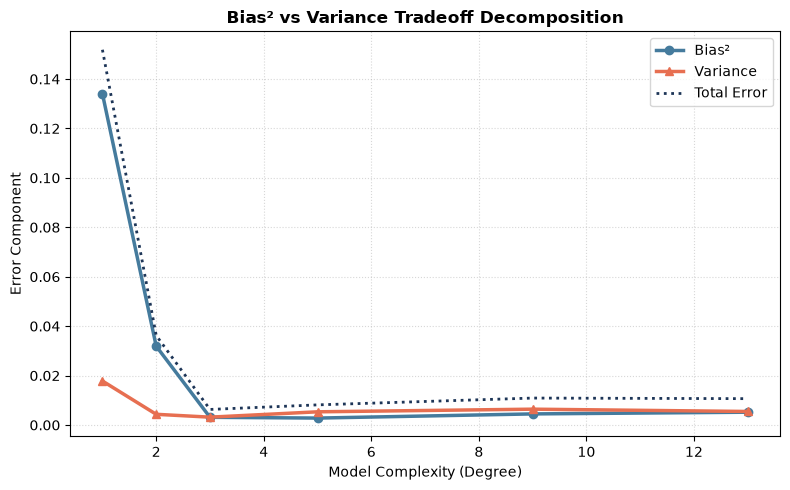

In [3]:
n_bootstraps = 100
test_x = np.linspace(0.1, 0.9, 30)[:, None]
true_y = true_target(test_x).ravel()

evaluated_degs = [1, 2, 3, 5, 9, 13]
bias_sq_list, var_list = [], []

for d in evaluated_degs:
    preds = np.zeros((n_bootstraps, len(test_x)))
    for b in range(n_bootstraps):
        boot_idx = np.random.choice(n_samples, size=n_samples, replace=True)
        xb, yb = x_train[boot_idx, None], y_train[boot_idx]
        mb = make_pipeline(PolynomialFeatures(d), Ridge(alpha=1e-6)).fit(xb, yb)
        preds[b] = mb.predict(test_x)
    mean_pred = np.mean(preds, axis=0)
    bias_sq = np.mean((mean_pred - true_y) ** 2)
    variance = np.mean(np.var(preds, axis=0))
    bias_sq_list.append(bias_sq)
    var_list.append(variance)

plt.figure(figsize=(8, 5))
plt.plot(evaluated_degs, bias_sq_list, color='#457b9d', lw=2.5, marker='o', label='Bias²')
plt.plot(evaluated_degs, var_list, color='#e76f51', lw=2.5, marker='^', label='Variance')
plt.plot(evaluated_degs, np.array(bias_sq_list) + np.array(var_list), color='#1d3557', lw=2, linestyle=':', label='Total Error')
plt.title("Bias² vs Variance Tradeoff Decomposition", fontweight='bold')
plt.xlabel("Model Complexity (Degree)")
plt.ylabel("Error Component")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()
